# 02b · Baselines, parte 2: backtest y comparación (Gate 2)

Tres modelos con el mismo arnés (63 orígenes, 2021-01-04 → 2025-10-06, h=1..12, ventana expansiva, reajuste en cada origen): `seasonal_naive`, `fourier_arma101` (K=2, ARMA(1,0,1), trend c) y `fourier_arima012` (K=2, ARIMA(0,1,2), trend n). Los órdenes se eligieron con 2012–2020 y quedan fijos (no se re-selecciona por origen: limitación). Pronóstico = `expm1` del pronóstico en log1p, es decir una mediana, no una media; eso explica parte del sesgo negativo. Las métricas de la comparación usan exactamente los mismos targets para los tres modelos.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from fires import compare
from fires.backtest import RESULTS, load_series
from fires.metrics import comparison_table

pd.set_option('display.width', 200)
fcs = compare.load_forecasts()
table = comparison_table(fcs)
table.to_csv(RESULTS / 'metrics' / 'gate2_comparison.csv', index=False)
for m in ('fourier_arma101', 'fourier_arima012'):
    log = pd.read_csv(RESULTS / 'forecasts' / f'{m}_fitlog.csv')
    print(m, 'no convergidos:', int((~log['converged']).sum()), 'de', len(log), '| excepciones:', int(log['error'].notna().sum()))
print('filas con y_true NaN (apagones), descartadas en los tres modelos:', int(fcs['seasonal_naive']['y_true'].isna().sum()))

fourier_arma101 no convergidos: 0 de 63 | excepciones: 0
fourier_arima012 no convergidos: 0 de 63 | excepciones: 0
filas con y_true NaN (apagones), descartadas en los tres modelos: 19


In [2]:
s = table[table['h'].isin([1, 4, 8, 12])]
s.round(3)

,eval_set,h,model,mae,rmse,bias,n,mae_ratio_vs_naive
0,all,1,fourier_arima012,3757.893,8483.444,-1431.742,60,0.472
1,all,1,fourier_arma101,3822.922,8685.901,-1958.438,60,0.480
2,all,1,seasonal_naive,7957.850,16376.793,557.950,60,1.000
9,all,4,fourier_arima012,3935.336,8214.407,-1089.090,63,0.518
10,all,4,fourier_arma101,3975.932,8859.884,-2069.293,63,0.523
11,all,4,seasonal_naive,7604.016,17485.139,29.667,63,1.000
21,all,8,fourier_arima012,4455.560,9127.689,-1274.752,63,0.586
22,all,8,fourier_arma101,4559.259,10388.375,-2568.039,63,0.600
23,all,8,seasonal_naive,7598.556,17485.085,35.127,63,1.000
33,all,12,fourier_arima012,4709.634,9539.886,-1650.132,62,0.612


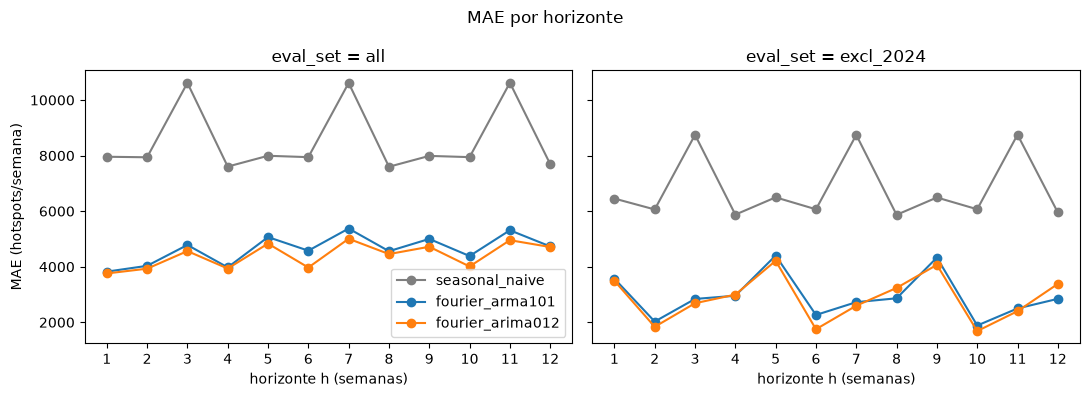

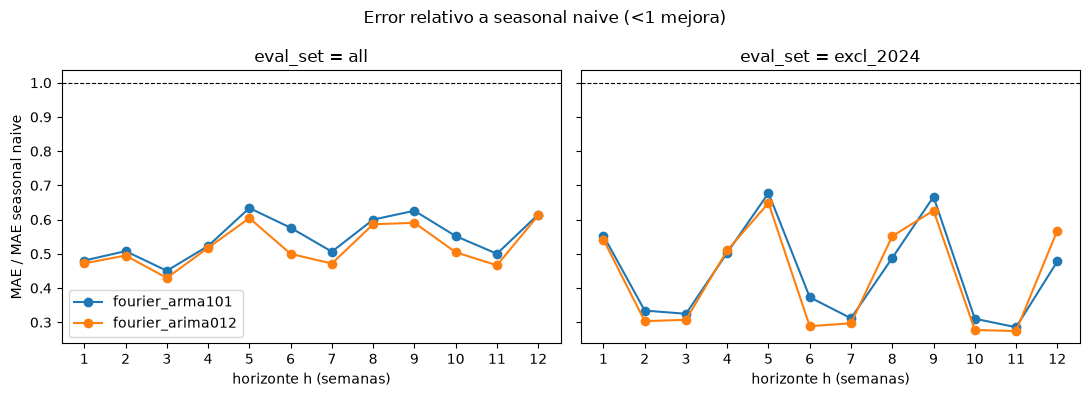

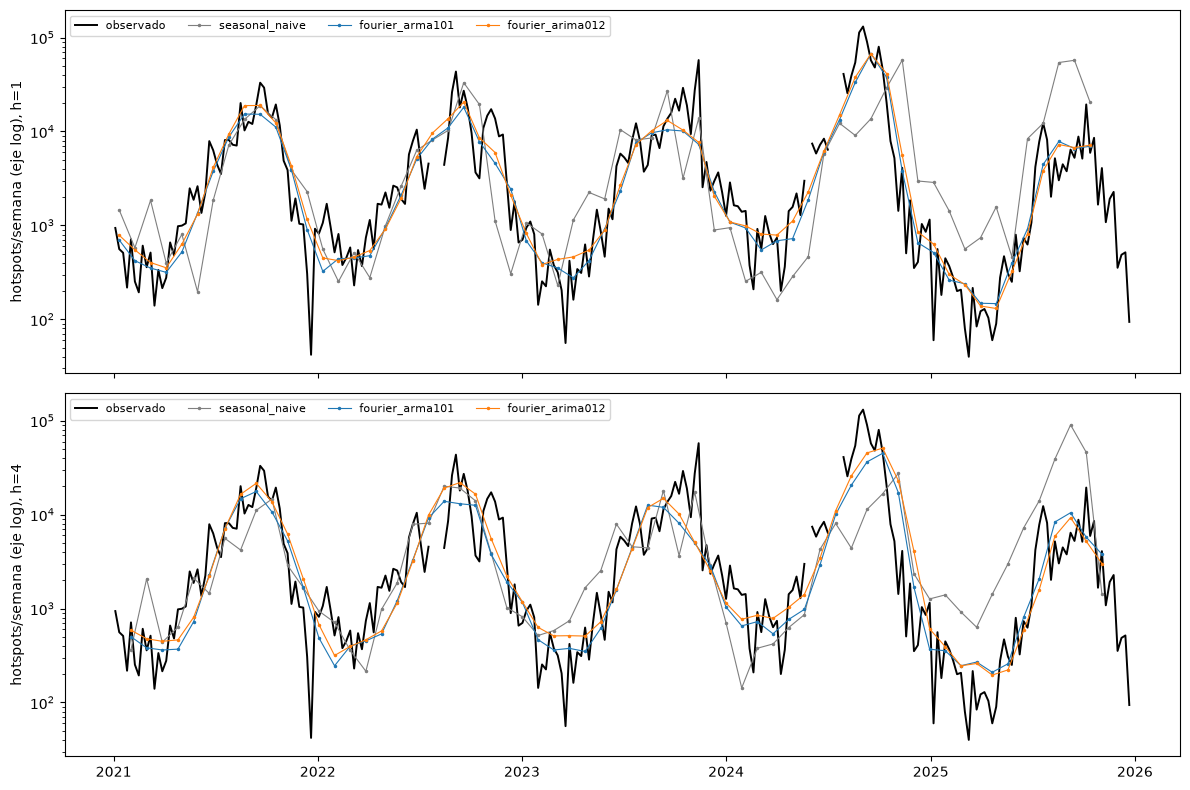

In [3]:
hot = load_series()['hotspots']
compare.plot_mae(table); compare.plot_ratio(table); compare.plot_forecasts(fcs, hot)
plt.show()

## Conclusión

Los dos modelos Fourier-ARIMA ganan a seasonal naive en todos los horizontes y en ambos conjuntos: el MAE baja a 0.43–0.63 del de naive con todos los targets (media 0.52 para d=1 y 0.55 para d=0) y a 0.27–0.68 sin 2024. La mejora es mayor a h corto (ratio ≈ 0.47–0.48 en h=1) y se reduce hacia h=12 (≈ 0.61).

d=1 (`fourier_arima012`) es mejor o igual con todos los targets en los 12 horizontes (ratio medio 0.52 contra 0.55). Sin 2024 los dos casi empatan, y d=0 (`fourier_arma101`) es algo mejor en h=4, 8 y 12 (en h=12, ratio 0.48 contra 0.57). Es decir, la corrección de nivel de d=1 pesa sobre todo con 2024 incluido, y sin ese año la diferencia entre A y B es pequeña.

Sesgo: los dos Fourier subestiman (bias negativo de −400 a −3 100 hotspots/semana, mayor en A), en parte porque son medianas y no medias. Seasonal naive tiene bias cercano a 0 (+8 a +560) con todos los targets, pero sobreestima en +1 300 a +2 600 sin 2024, porque copia el pico de 2024 al año siguiente.